# Code Path Visualization

这个 notebook 只做一件事：给定一个目录路径，递归查找其中所有 `code.py`（或自定义 pattern），导入并调用每个文件的 `generate_input()` 与 `main()`，按 ARC 0-9 标准颜色可视化输入/输出网格。

默认目标路径：`/home/lixinyu/snap/new/ceshi/code/6ffbe589`，可在最后一格修改 `variants_path`。

## 函数分组导览

- **Cell 1**：环境/常量。把 `ceshi/` 注入 `sys.path`（让被加载的 `code.py` 能 `import arc_utils`），并定义 ARC 0-9 标准 colormap。
- **Cell 2**：绘图层。
  - `as_grid`：把任意输入规范成 2D int ndarray。
  - `draw_arc_grid` / `_add_grid_axes`：底层画图。
  - `show_grid_pair`：把一对 input/output 并排画出来（唯一对外画图函数）。
- **Cell 3**：代码加载层。
  - `load_module_from_path`：动态把 `.py` 文件导入成模块。
  - `discover_code_files`：递归查找代码文件。
  - `supports_visualization`：检查模块有没有 `generate_input` + `main`。
  - `call_generate_input` / `generate_io_pair`：跑一遍代码，得到一对 IO。
- **Cell 4**：编排层。
  - `visualize_code_files`：对一组文件批量可视化。
  - `visualize_code_path`：从根路径直接出图（最常用入口）。
- **Cell 5**：调用入口，改 `variants_path` 就能换可视化目标。

In [1]:
from __future__ import annotations

import hashlib
import importlib.util
import inspect
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.colors import BoundaryNorm, ListedColormap

# 让动态加载的 code.py 能 `from arc_utils import ...`，arc_utils.py 与本 notebook 同级。
CESHI_DIR = Path("/home/lixinyu/snap/new/ceshi").resolve()
if str(CESHI_DIR) not in sys.path:
    sys.path.insert(0, str(CESHI_DIR))

ARC_COLORS = [
    "#000000",
    "#0074D9",
    "#FF4136",
    "#2ECC40",
    "#FFDC00",
    "#AAAAAA",
    "#F012BE",
    "#FF851B",
    "#7FDBFF",
    "#870C25",
]
ARC_CMAP = ListedColormap(ARC_COLORS)
ARC_NORM = BoundaryNorm(np.arange(-0.5, 10.5, 1), ARC_CMAP.N)

In [2]:
# ----------------------------------------------------------------------
# 绘图相关的尺寸常量（单位：英寸）。
#   - CELL_SIZE_INCH: 一个网格单元在图上画多大；越大整张图越大。
#   - LEFT/RIGHT/TOP/BOTTOM_MARGIN_INCH: 整张 figure 四周留白。
#   - PAIR_GAP_INCH: 同一对 input/output 网格之间的水平间距。
# ----------------------------------------------------------------------
CELL_SIZE_INCH = 0.1
LEFT_MARGIN_INCH = 0.45
RIGHT_MARGIN_INCH = 0.45
TOP_MARGIN_INCH = 0.8
BOTTOM_MARGIN_INCH = 0.35
PAIR_GAP_INCH = 0.8


def as_grid(grid):
    """把任意输入（list / tuple / ndarray）规范成一个二维 int ndarray。

    用于在画图前统一类型并做最基本的形状校验：必须是二维、不能为空，
    否则直接抛 ValueError，防止后面 matplotlib 报难懂的错。
    """
    arr = np.asarray(grid, dtype=int)
    if arr.ndim != 2:
        raise ValueError(f"Expected a 2D grid, got shape {arr.shape}")
    if arr.size == 0:
        raise ValueError("Grid is empty.")
    return arr


def _grid_extent_inch(grid):
    """返回画出一个网格所需的物理宽高（英寸），用来精确摆放子图。"""
    arr = as_grid(grid)
    rows, cols = arr.shape
    return cols * CELL_SIZE_INCH, rows * CELL_SIZE_INCH


def draw_arc_grid(ax, grid, title=""):
    """在已有的 matplotlib `ax` 上画一个 ARC 网格。

    - 使用 ARC 0-9 的标准 10 色 colormap。
    - 在每个单元之间画白色细网格线，便于人眼对齐。
    - 标题里附带 `H x W` 的形状信息。
    """
    arr = np.asarray(as_grid(grid), dtype=int).copy()
    ax.imshow(arr, cmap=ARC_CMAP, norm=ARC_NORM, interpolation="nearest")
    ax.set_title(f"{title}\n{arr.shape[0]}x{arr.shape[1]}", fontsize=11)
    ax.set_xticks(np.arange(-0.5, arr.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, arr.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    ax.set_aspect("equal")


def _add_grid_axes(fig, grid, x_inch, y_inch, fig_w, fig_h, max_rows, title=""):
    """在 figure 上按“英寸坐标”精确放置一个子图来画 grid。

    不同网格高度不同时，按 `max_rows` 把短一些的网格在垂直方向居中对齐，
    避免画出来上下乱跳。返回创建好的 axes 对象。
    """
    arr = as_grid(grid)
    rows, cols = arr.shape
    width_inch = cols * CELL_SIZE_INCH
    height_inch = rows * CELL_SIZE_INCH
    vertical_offset = (max_rows - rows) * CELL_SIZE_INCH / 2

    ax = fig.add_axes([
        x_inch / fig_w,
        (y_inch + vertical_offset) / fig_h,
        width_inch / fig_w,
        height_inch / fig_h,
    ])
    draw_arc_grid(ax, arr, title=title)
    return ax


def show_grid_pair(input_grid, output_grid=None, title=""):
    """把一对 input/output 网格并排画到同一张 figure 上并 `plt.show()`。

    - `output_grid` 为 None 时只画一个 input。
    - figure 的大小根据两个网格的实际尺寸动态算出，不会出现拉伸。
    - 是本 notebook 唯一对外输出图像的函数。
    """
    input_arr = as_grid(input_grid)
    input_w, input_h = _grid_extent_inch(input_arr)

    if output_grid is None:
        fig_w = LEFT_MARGIN_INCH + input_w + RIGHT_MARGIN_INCH
        fig_h = TOP_MARGIN_INCH + input_h + BOTTOM_MARGIN_INCH
        fig = plt.figure(figsize=(fig_w, fig_h))
        _add_grid_axes(
            fig,
            input_arr,
            LEFT_MARGIN_INCH,
            BOTTOM_MARGIN_INCH,
            fig_w,
            fig_h,
            max_rows=input_arr.shape[0],
            title=title or "Grid",
        )
    else:
        output_arr = as_grid(output_grid)
        output_w, _ = _grid_extent_inch(output_arr)
        max_rows = max(input_arr.shape[0], output_arr.shape[0])
        fig_w = LEFT_MARGIN_INCH + input_w + PAIR_GAP_INCH + output_w + RIGHT_MARGIN_INCH
        fig_h = TOP_MARGIN_INCH + max_rows * CELL_SIZE_INCH + BOTTOM_MARGIN_INCH
        fig = plt.figure(figsize=(fig_w, fig_h))
        _add_grid_axes(
            fig,
            input_arr,
            LEFT_MARGIN_INCH,
            BOTTOM_MARGIN_INCH,
            fig_w,
            fig_h,
            max_rows=max_rows,
            title=f"{title} Input".strip(),
        )
        _add_grid_axes(
            fig,
            output_arr,
            LEFT_MARGIN_INCH + input_w + PAIR_GAP_INCH,
            BOTTOM_MARGIN_INCH,
            fig_w,
            fig_h,
            max_rows=max_rows,
            title=f"{title} Output".strip(),
        )

    plt.show()

In [3]:
def load_module_from_path(module_path):
    """把任意路径下的 .py 文件动态导入成一个 Python 模块对象。

    - 不需要这个文件位于 `sys.path` 上，也不要求是 package。
    - 内部用文件路径的 sha1 前缀拼模块名，确保不同路径的同名 .py（比如
      多个 `code.py`）不会互相覆盖。
    - 加载完后可以直接 `module.generate_input()` / `module.main(grid)`。
    """
    module_path = Path(module_path).expanduser().resolve()
    module_key = hashlib.sha1(str(module_path).encode("utf-8")).hexdigest()[:12]
    module_name = f"arc_viz_{module_path.stem}_{module_key}"
    spec = importlib.util.spec_from_file_location(module_name, module_path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Could not load module spec for {module_path}")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


def discover_code_files(root_path, pattern="*.py"):
    """递归查找一个目录下所有匹配 `pattern` 的代码文件。

    - `pattern` 可以是 `"*.py"`、`"code.py"`、`"main.py"` 等任意 glob。
    - 自动过滤掉 `__init__.py`。
    - 如果 `root_path` 直接指向一个文件，就只返回它自己。
    - 返回的列表按路径字典序排好，保证不同机器上顺序一致。
    """
    root = Path(root_path).expanduser().resolve()
    if not root.exists():
        raise FileNotFoundError(root)
    if root.is_file():
        return [root]
    return sorted(path for path in root.rglob(pattern) if path.name != "__init__.py")


def supports_visualization(module):
    """判断一个模块是否能被本 notebook 可视化。

    要求模块里同时存在可调用的 `generate_input` 和 `main` 两个函数；
    任何一个缺失都会被 `visualize_code_files` 标为 skipped。
    """
    return callable(getattr(module, "generate_input", None)) and callable(getattr(module, "main", None))


def call_generate_input(generate_input_fn, seed=0):
    """用统一接口调用一个 `generate_input` 函数，自动适配不同签名。

    现实中 `generate_input` 写法有三种：
      1. `def generate_input():`                ← 完全不带参数，最常见。
      2. `def generate_input(seed, /):`         ← 位置参数（POSITIONAL_ONLY）。
      3. `def generate_input(*, seed):` / `def generate_input(seed):` 等。

    本函数会用 `inspect` 看签名，按需把传入的 `seed` 喂进去；如果函数
    本身不要参数，则 `seed` 被忽略（这是当前大部分 code.py 的情况）。
    """
    signature = inspect.signature(generate_input_fn)
    required = [
        param
        for param in signature.parameters.values()
        if param.kind in (inspect.Parameter.POSITIONAL_ONLY, inspect.Parameter.POSITIONAL_OR_KEYWORD)
        and param.default is inspect.Signature.empty
    ]
    if not required:
        return generate_input_fn()
    if len(required) == 1:
        param = required[0]
        if param.kind is inspect.Parameter.POSITIONAL_ONLY:
            return generate_input_fn(seed)
        return generate_input_fn(**{param.name: seed})
    raise TypeError(f"Unsupported generate_input signature: {signature}")


def generate_io_pair(module, seed=0):
    """从一个已加载的模块产出一对 (input_grid, output_grid)。

    流程：
      1. 调 `module.generate_input()` 生成一个新输入网格。
      2. 把输入拷贝一份喂给 `module.main(...)`，得到对应输出。
      3. 两个网格都规范成 2D int ndarray 再返回。
    """
    input_grid = as_grid(call_generate_input(module.generate_input, seed=seed))
    output_grid = as_grid(module.main(input_grid.copy()))
    return input_grid, output_grid

In [4]:
def visualize_code_files(code_files, *, root=None, seed=0, num_examples=1):
    """对一组 code 文件做批量可视化。

    参数：
      - `code_files`: 已经找好的代码文件路径列表（一般来自 `discover_code_files`）。
      - `root`: 可选；只用来在标题里显示相对路径，让输出更整洁。
      - `seed`: 起始 seed；第 i 个例子用 `seed + i`。当 `generate_input`
        本身不接参数时此值会被忽略（详见 `call_generate_input` 注释）。
      - `num_examples`: 每个文件生成并画多少对 IO，默认 1。

    流程（对每个文件）：
      1. 动态加载模块；如果缺 `generate_input/main` 就 skip。
      2. 在 markdown 里打出文件名/相对路径作为小标题。
      3. 循环 `num_examples` 次，每次产出一对 (input, output) 并画出来。
      4. 单文件失败不影响其他文件，异常会被收集到 errors 列表。

    返回：一个总结字典，包含扫描数、成功数、跳过列表、错误列表等。
    """
    paths = [Path(p).expanduser().resolve() for p in code_files]
    root = Path(root).expanduser().resolve() if root is not None else None

    def rel_path_for(cf: Path) -> Path:
        if root is not None and root.is_dir():
            try:
                return cf.relative_to(root)
            except ValueError:
                pass
        return Path(cf.name)

    visualized = 0
    pairs_visualized = 0
    skipped = []
    errors = []

    for code_file in paths:
        try:
            module = load_module_from_path(code_file)
            if not supports_visualization(module):
                skipped.append((code_file, "missing generate_input() or main()"))
                continue

            rel_path = rel_path_for(code_file)
            display(Markdown(f"### `{rel_path}`"))
            for example_idx in range(num_examples):
                example_seed = seed + example_idx
                input_grid, output_grid = generate_io_pair(module, seed=example_seed)
                show_grid_pair(input_grid, output_grid, title=f"{code_file.stem} #{example_idx + 1}")
                pairs_visualized += 1
            visualized += 1
        except Exception as exc:
            errors.append((code_file, exc))

    where = f" in {root}" if root is not None else ""
    print(f"Scanned {len(paths)} files{where}")
    print(f"Visualized files: {visualized}")
    print(f"Visualized pairs: {pairs_visualized}")

    if skipped:
        print(f"Skipped: {len(skipped)}")
        for code_file, reason in skipped:
            print(f"  - {rel_path_for(code_file)}: {reason}")

    if errors:
        print(f"Errors: {len(errors)}")
        for code_file, exc in errors:
            print(f"  - {rel_path_for(code_file)}: {type(exc).__name__}: {exc}")

    return {
        "root": root,
        "scanned": len(paths),
        "visualized": visualized,
        "examples_per_file": num_examples,
        "pairs_visualized": pairs_visualized,
        "skipped": skipped,
        "errors": errors,
    }


def visualize_code_path(root_path, seed=0, max_files=None, pattern="*.py", num_examples=1):
    """从一个根路径直接做批量可视化（最常用的入口函数）。

    相比 `visualize_code_files`，它多做了一步“先去找文件”：
      1. 用 `discover_code_files(root_path, pattern)` 递归找出所有匹配文件。
      2. 如果指定了 `max_files`，只取前 N 个（按字典序）。
      3. 把剩下的文件交给 `visualize_code_files` 真正画出来。

    参数语义和 `visualize_code_files` 一致，多了 `pattern` / `max_files`。
    """
    root = Path(root_path).expanduser().resolve()
    code_files = discover_code_files(root, pattern=pattern)
    if max_files is not None:
        code_files = code_files[:max_files]
    return visualize_code_files(code_files, root=root, seed=seed, num_examples=num_examples)

### `D1/2/code.py`

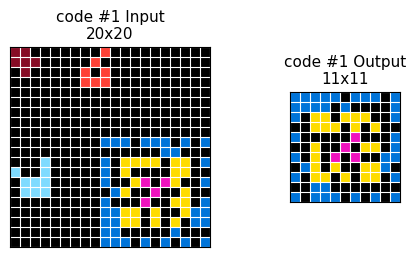

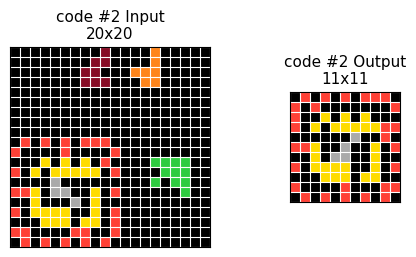

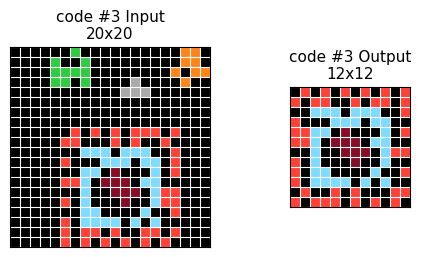

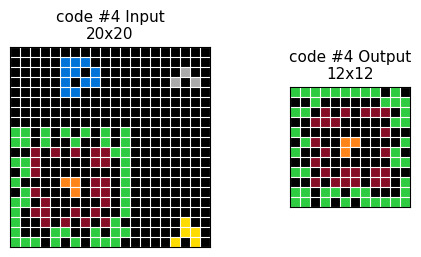

### `D1/3/code.py`

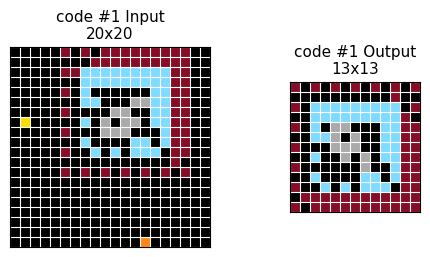

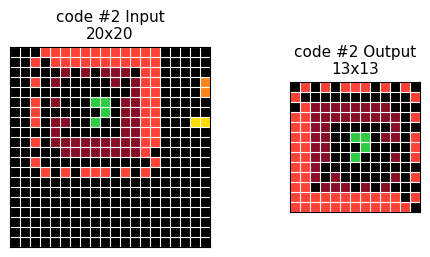

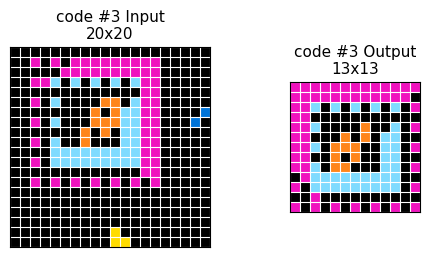

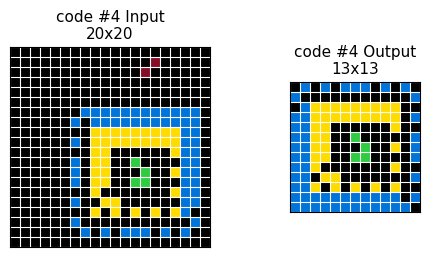

### `D14/1/code.py`

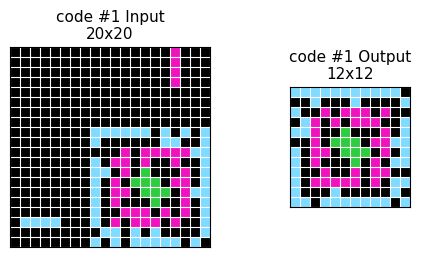

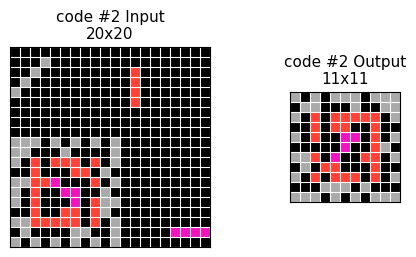

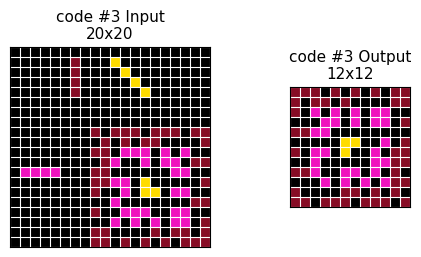

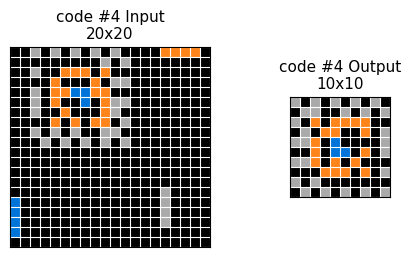

### `D17/0/code.py`

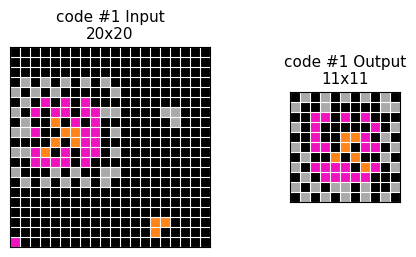

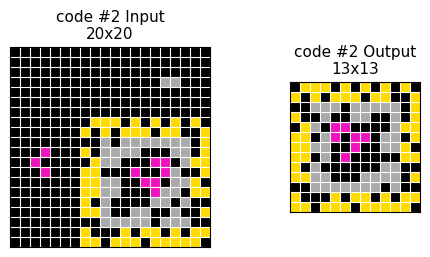

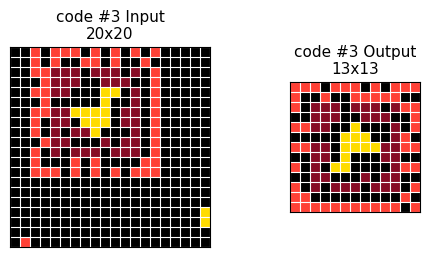

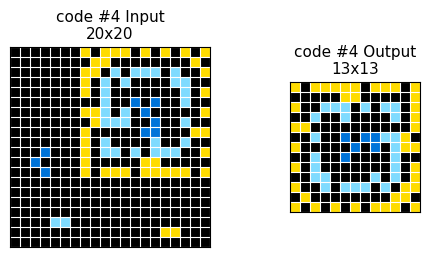

### `D17/2/code.py`

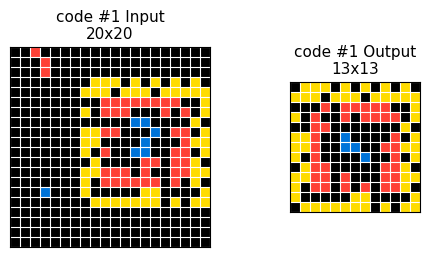

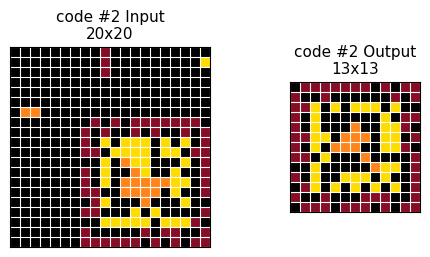

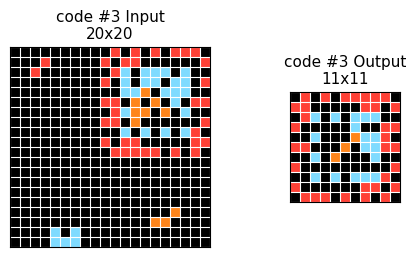

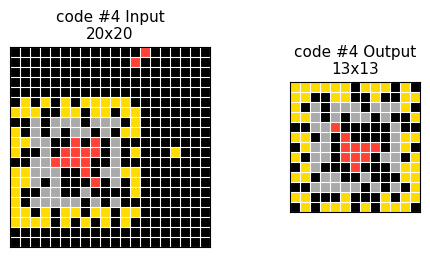

### `D18/0/code.py`

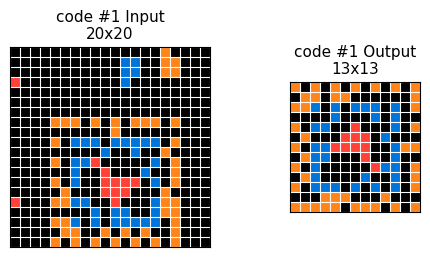

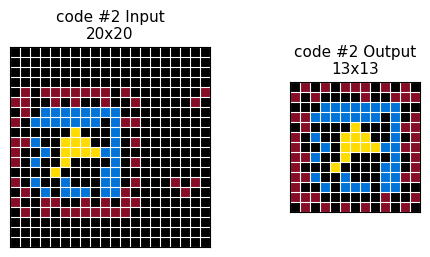

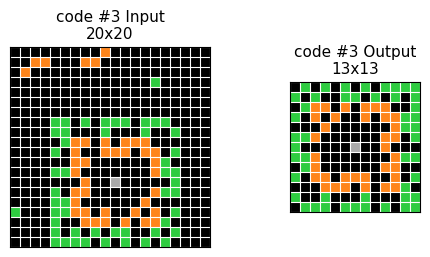

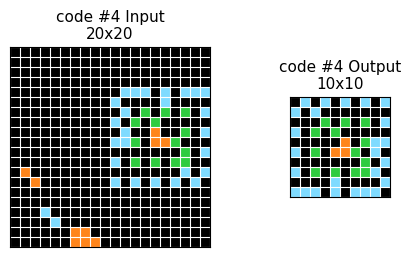

### `D18/1/code.py`

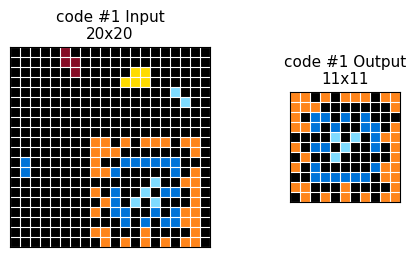

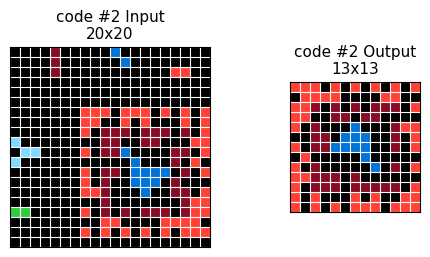

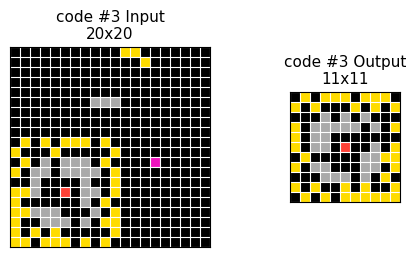

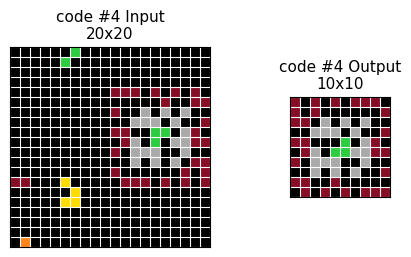

### `D2/0/code.py`

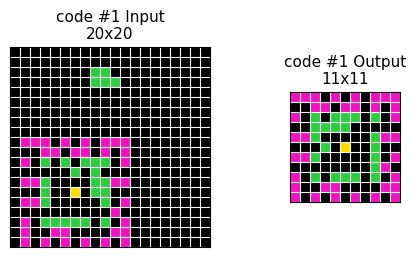

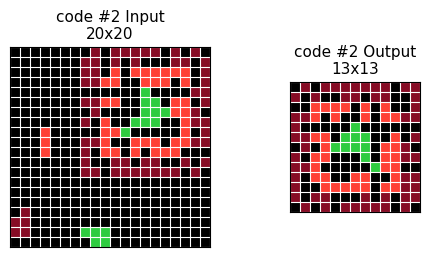

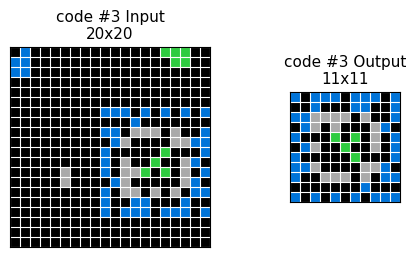

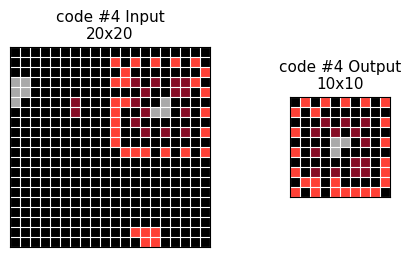

### `D2/2/code.py`

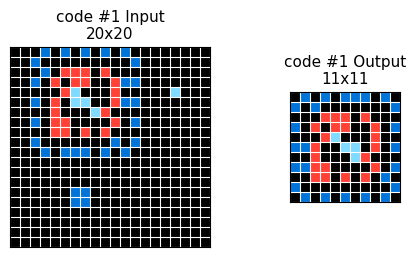

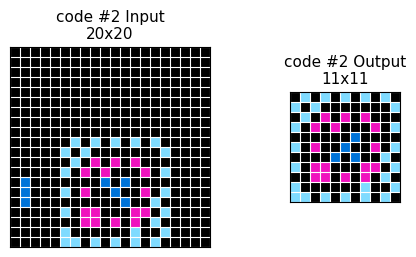

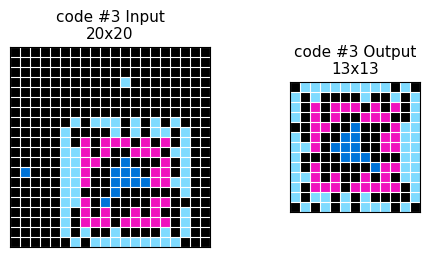

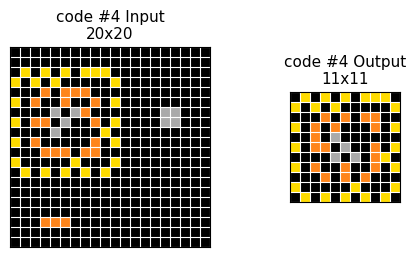

### `D3/0/code.py`

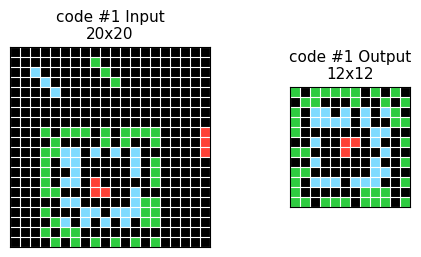

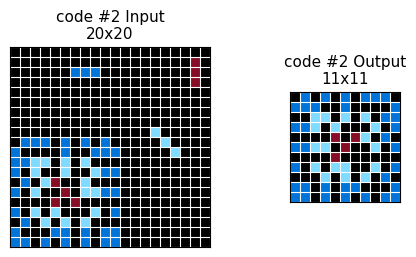

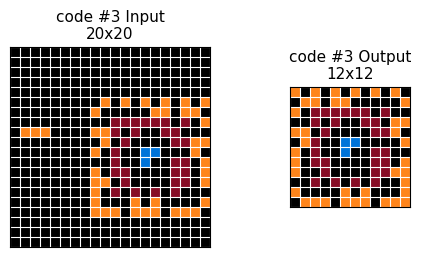

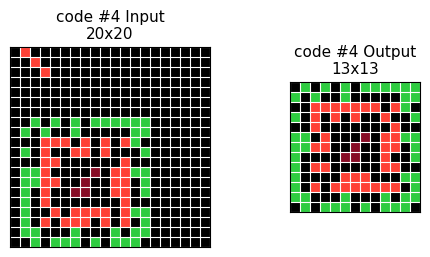

### `D4/1/code.py`

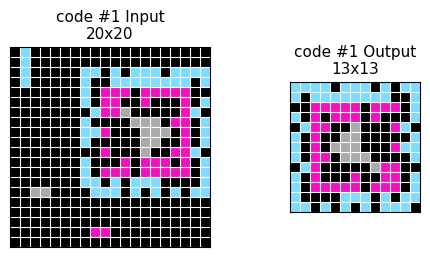

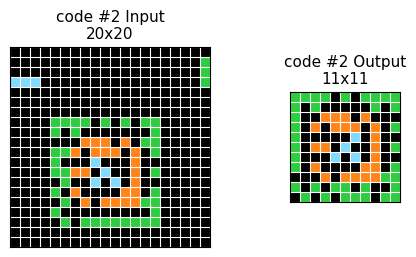

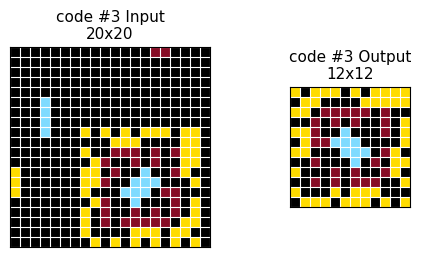

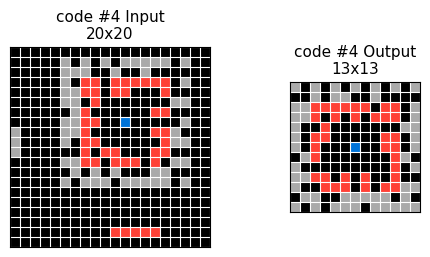

### `D4/3/code.py`

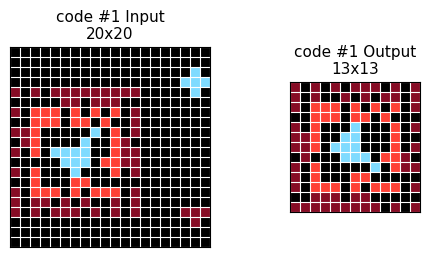

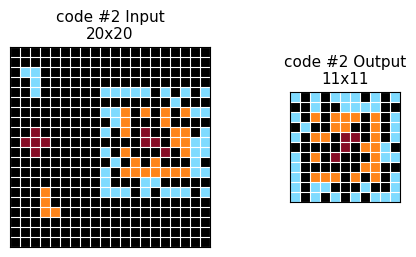

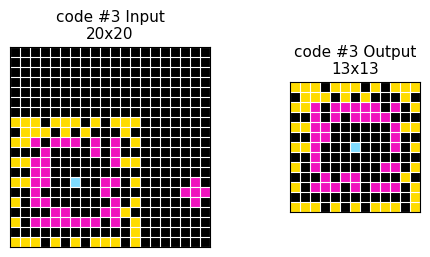

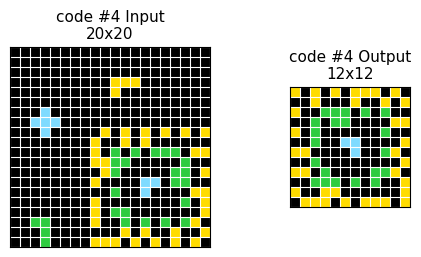

### `D5/1/code.py`

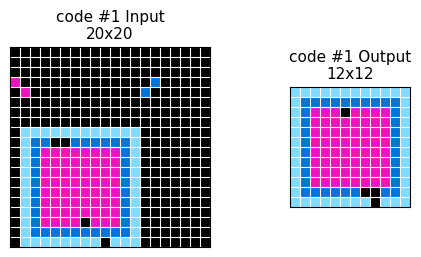

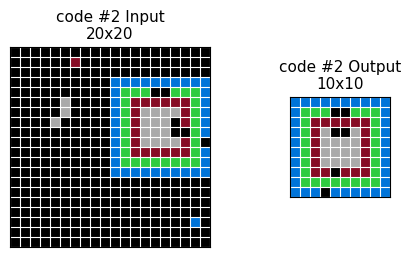

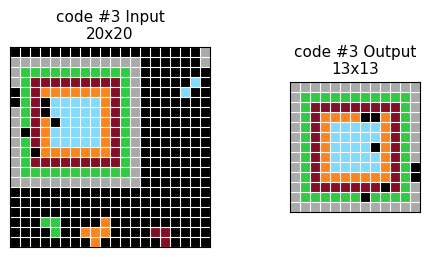

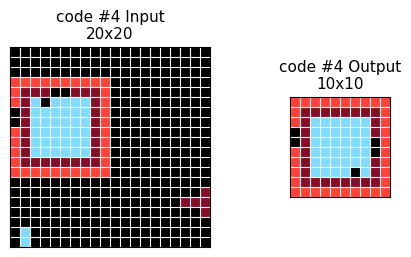

### `D6/2/code.py`

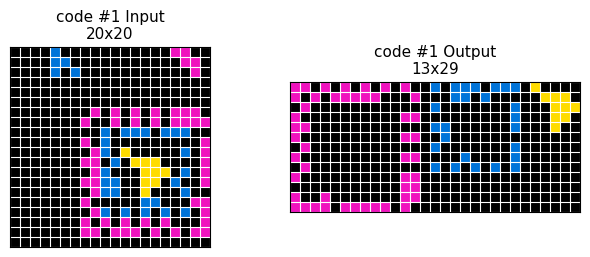

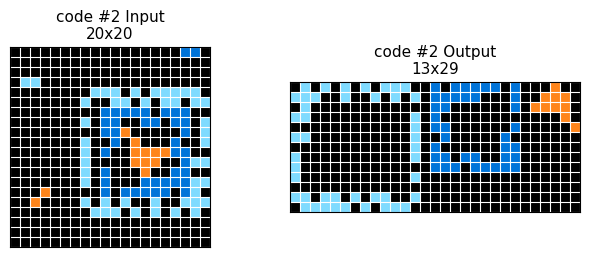

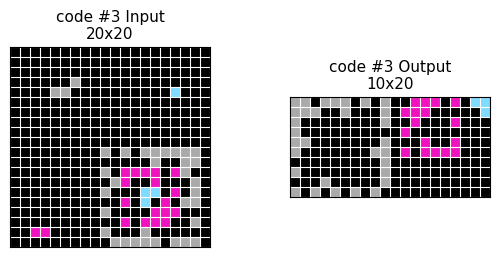

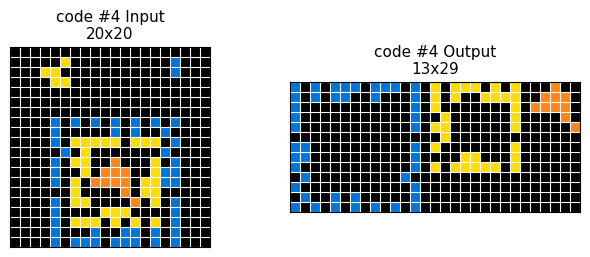

### `D7/1/code.py`

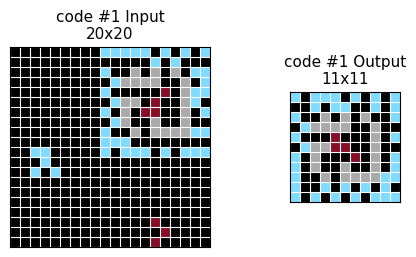

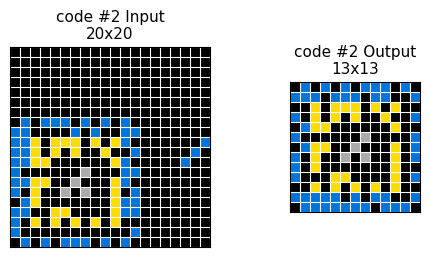

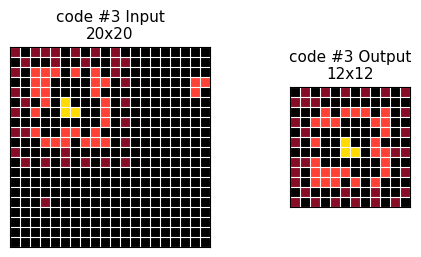

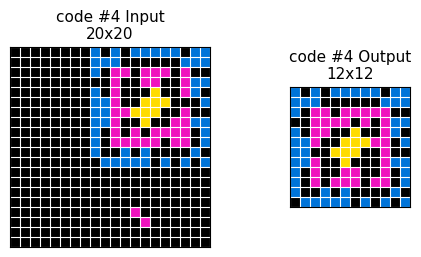

### `D7/2/code.py`

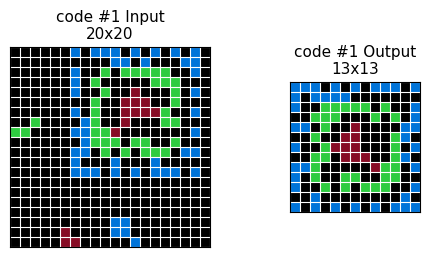

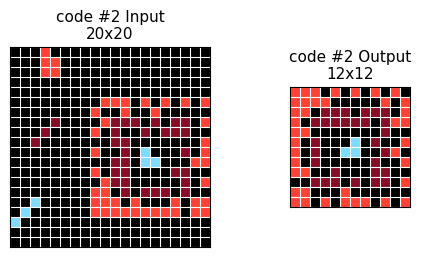

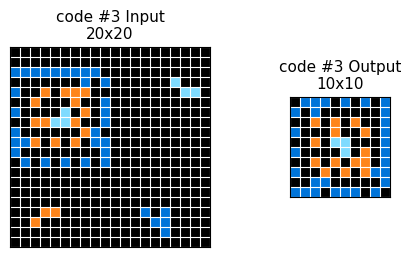

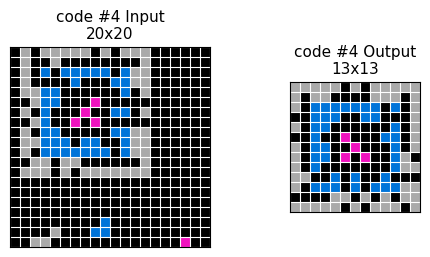

### `D8/0/code.py`

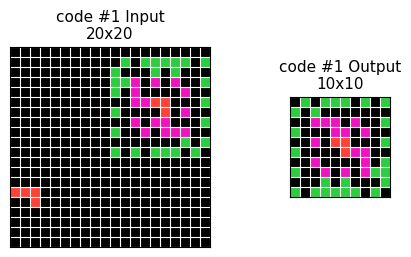

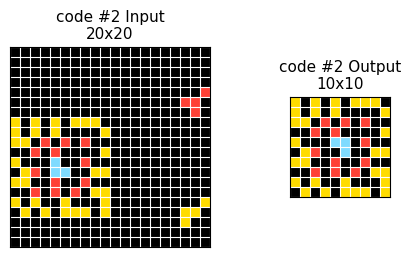

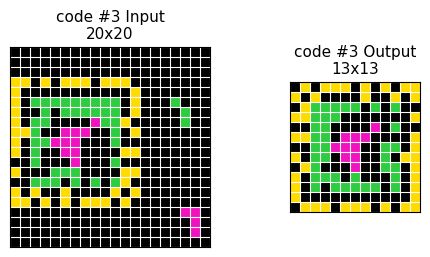

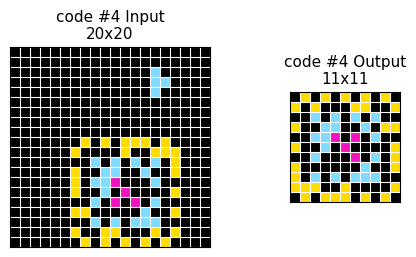

### `D8/1/code.py`

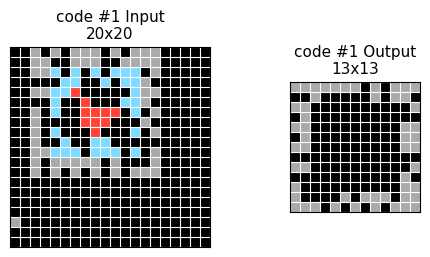

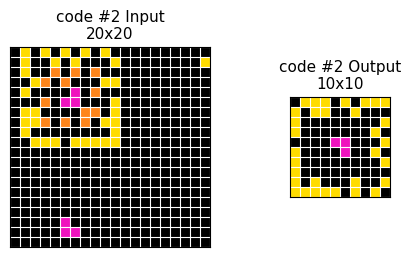

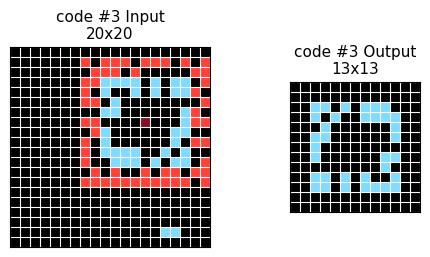

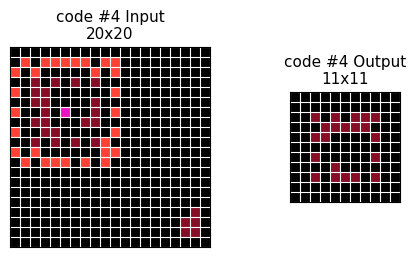

### `D8/2/code.py`

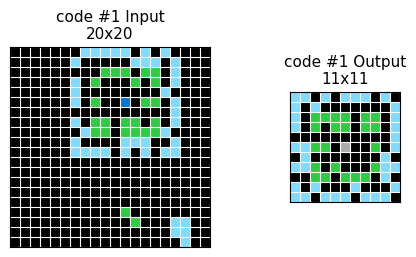

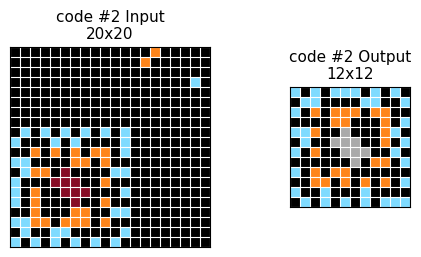

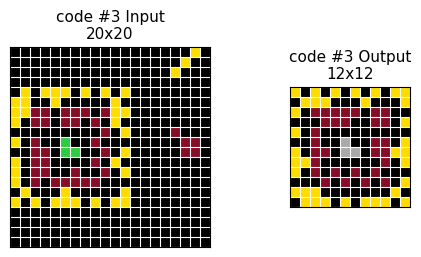

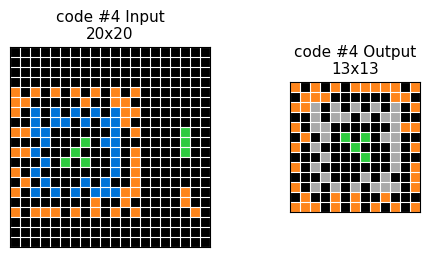

Scanned 19 files in /home/lixinyu/snap/new/ceshi/code/6ffbe589
Visualized files: 19
Visualized pairs: 76


{'root': PosixPath('/home/lixinyu/snap/new/ceshi/code/6ffbe589'),
 'scanned': 19,
 'visualized': 19,
 'examples_per_file': 4,
 'pairs_visualized': 76,
 'skipped': [],
 'errors': []}

In [6]:
variants_path = "/home/lixinyu/snap/new/ceshi/code/6ffbe589"
# variants_path = "/home/lixinyu/snap/new/ceshi/code/78332cb0/D14"
variants_seed = 0
variants_examples = 4
max_files = None  # 例如设为 5；None 表示该路径下全部匹配的 code.py

variants_summary = visualize_code_path(
    variants_path,
    seed=variants_seed,
    max_files=max_files,
    pattern="code.py",
    num_examples=variants_examples,
)
variants_summary